In [1]:
import myhda_ur as hda

In [2]:
hdata = hda.load_scifate()

### Expression-distance clusters

gene x cell expression matrix -> distance matrix -> cluster -> visualize with PCA

In [3]:
# Initialize a temporary subset object for the selected cells 
subset_cells_ = hdata[:2000, :600]  # 2000 genes x 600 cells

In [4]:
# Compute cell-cell similarity of the selected cells using normalized gene expression values 
hdata.compute_similarity(
    data=subset_cells_,
    key="X",
    kind="cell",
    method="correlation"
)

sim_cells_ = hdata.similarities["correlation_X_cell"]

Similarity "correlation_X_cell" stored! 



In [5]:
# Cluster the cells using Spectral Clustering
hdata.cluster_spectral(
        sim = sim_cells_,                                 
        kind = "cell",
        k = 6
    )

cl_spec_cells_ = hdata.clusters["spectral_k6_cell"]

Cluster "spectral_k6_cell" stored! 



In [6]:
# Reduce the dimensions into 2D using PCA 
hdata.reduce_PCA(
    data = subset_cells_,
    key = "X",
    kind = "cell"
)

em_cells_ = hdata.embeddings["pca_cell"]

PCA embedding "pca_cell" stored! 



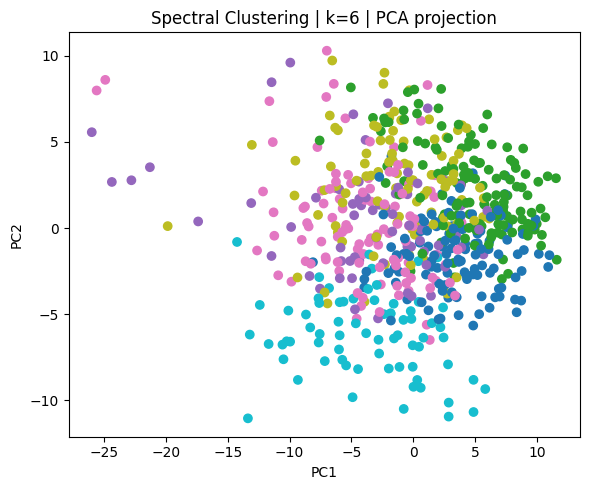

In [7]:
# Visualize 
hda.visualize.scatter(
    cluster=cl_spec_cells_,
    embedding=em_cells_,
    title="Spectral Clustering | k=6 | PCA projection",
    show_label=False
)

### PCA-based clusters 

gene x cell expression matrix -> PCA (cell x PC) -> distance matrix -> cluster

In [ ]:
# PCA for representation - cell x PC matrix
hdata.compute_PCA(
    data=subset_cells_,
    key="X",
    kind="cell",
    n_pc=20
)

pc_matrix = hdata.layers["pca"]    

PCA matrix X x 20 PCs stored in data.layers["pca"] 

PCA embedding "pca_cell_PC20" stored! 



In [9]:
# Compute cell-cell distance matrix in PC space
hdata.compute_similarity(
    data=subset_cells_,
    key="pca",
    method="correlation"
)

sim_pca_cells_ = hdata.similarities["correlation_pca_cell"]   

Similarity "correlation_pca_cell" stored! 



In [10]:
# Cluster in PC space
hdata.cluster_spectral(
    sim=sim_pca_cells_,
    kind="cell",
    k=6
)

cl_pca_cells_ = hdata.clusters["spectral_k6_cell"]

Cluster "spectral_k6_cell" stored! 



In [11]:
# Reuse the embeddings already stored by compute_PCA
em_pca_cells_ = hdata.embeddings['pca_cell_PC20']  

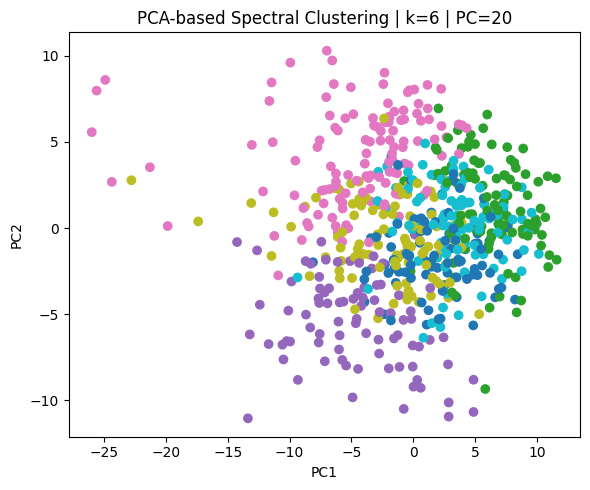

In [12]:
# Visualize 
hda.visualize.scatter(
    cluster=cl_pca_cells_,
    embedding=em_pca_cells_,
    title="PCA-based Spectral Clustering | k=6 | PC=20",
    show_label=False
)

PC = 5

PCA matrix X x 5 PCs stored in data.layers["pca"] 

PCA embedding "pca_cell_PC5" stored! 

Similarity "correlation_pca_cell" stored! 

Cluster "spectral_k6_cell" stored! 



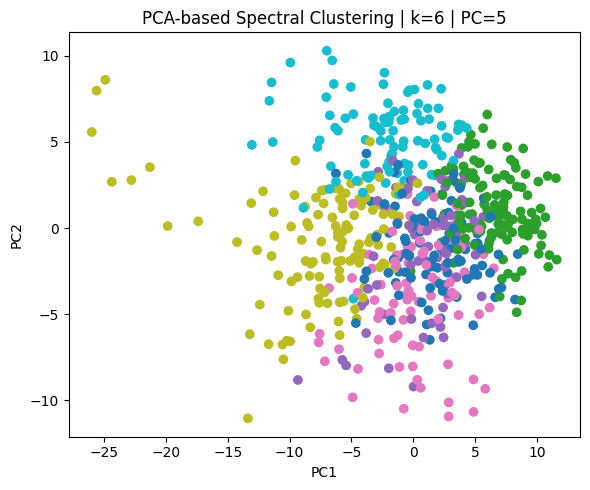

In [13]:
# PCA for representation - cell x PC matrix
hdata.compute_PCA(
    data=subset_cells_,
    key="X",
    kind="cell",
    n_pc=5
)

pc_matrix = hdata.layers["pca"]     

# Compute cell-cell distance matrix in PC space
hdata.compute_similarity(
    data=subset_cells_,
    key="pca",
    method="correlation"
)

sim1 = hdata.similarities["correlation_pca_cell"]  

# Cluster in PC space
hdata.cluster_spectral(
    sim=sim1,
    kind="cell",
    k=6
)

cl1= hdata.clusters["spectral_k6_cell"]

# Reuse the embeddings already stored by compute_PCA
em1= hdata.embeddings['pca_cell_PC5']  

# Visualize 
hda.visualize.scatter(
    cluster=cl1,
    embedding=em1,
    title="PCA-based Spectral Clustering | k=6 | PC=5",
    show_label=False
)

PC = 50

PCA matrix X x 50 PCs stored in data.layers["pca"] 

PCA embedding "pca_cell_PC50" stored! 

Similarity "correlation_pca_cell" stored! 

Cluster "spectral_k6_cell" stored! 



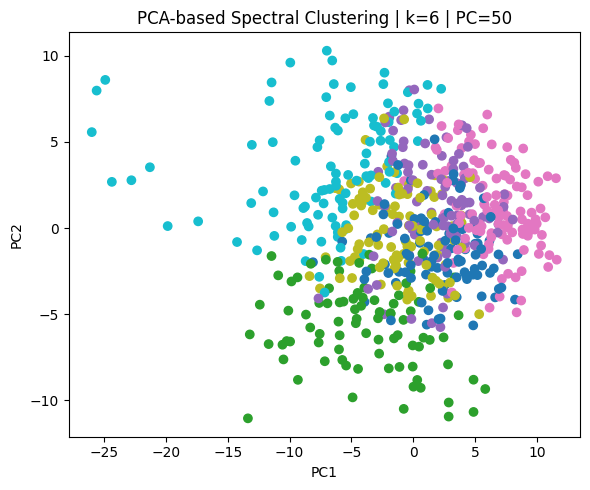

In [14]:
# PCA for representation - cell x PC matrix
hdata.compute_PCA(
    data=subset_cells_,
    key="X",
    kind="cell",
    n_pc=50
)

pc_matrix = hdata.layers["pca"]    

# Compute cell-cell distance matrix in PC space
hdata.compute_similarity(
    data=subset_cells_,
    key="pca",
    method="correlation"
)

sim2 = hdata.similarities["correlation_pca_cell"]  

# Cluster in PC space
hdata.cluster_spectral(
    sim=sim2,
    kind="cell",
    k=6
)

cl2 = hdata.clusters["spectral_k6_cell"]

# Reuse the embeddings already stored by compute_PCA
em2 = hdata.embeddings['pca_cell_PC50']  

# Visualize 
hda.visualize.scatter(
    cluster=cl2,
    embedding=em2,
    title="PCA-based Spectral Clustering | k=6 | PC=50",
    show_label=False
)